# Quantum Marketing Optimizer: Campaign Selection Using QAOA

**A college-level mini-project on quantum optimization with Qiskit, Qiskit Aer and QAOA**

---

## 1. Introduction

### The business problem
A marketing team has a fixed advertising budget and a list of possible campaigns. Every campaign has a **cost** and an **expected return**. Campaigns cannot be partially funded: each one is either **run (1)** or **not run (0)**. The team wants the combination of campaigns with the **largest total expected return** whose **total cost does not exceed the budget**.

This is a **0/1 knapsack problem**, a classic combinatorial optimization problem. With $n$ campaigns there are $2^n$ possible combinations, so exhaustive search becomes impractical as $n$ grows. That is why heuristics, and more recently quantum heuristics, are studied.

### Why QAOA?
The **Quantum Approximate Optimization Algorithm (QAOA)** is a hybrid quantum-classical algorithm for binary optimization:

1. Encode the objective function as a **cost Hamiltonian** $H_C$, a diagonal operator whose eigenvalue for each bitstring equals that bitstring's cost.
2. Prepare a quantum state using $p$ alternating layers of $e^{-i\gamma H_C}$ (cost layer) and $e^{-i\beta H_M}$ (mixer layer), controlled by $2p$ angles.
3. Measure the circuit. Low-cost bitstrings should appear with higher probability.
4. A **classical optimizer** adjusts the angles to minimize the measured average cost.

### What this notebook does
| Step | Content |
|---|---|
| 2 | Editable dataset of 5 campaigns |
| 3 | Mathematical formulation (binary program, budget constraint, penalty / QUBO) |
| 4 | Classical baselines: brute force (exact) and greedy |
| 5 | QAOA with Qiskit + Qiskit Aer, optimized by COBYLA |
| 6 | Comparison table |
| 7 | Visualizations |
| 8 | The actual QAOA circuit |
| 9 | Conclusion and honest limitations |

> **Honesty note.** QAOA is a *heuristic*. Everything reported below is computed live when you run the notebook. Nothing is hard-coded, and the notebook states clearly whether QAOA found the true optimum.

In [1]:
# Install dependencies (Colab-friendly). Qiskit >= 1.2 uses the modern (non-deprecated) APIs used here.
!pip install -q "qiskit>=1.2" "qiskit-aer>=0.15" pylatexenc

In [2]:
import itertools
import time
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator

print("Qiskit version     :", qiskit.__version__)
print("Qiskit Aer version :", qiskit_aer.__version__)

Qiskit version     : 2.6.2
Qiskit Aer version : 0.18.4


## 2. Dataset (editable)

Edit the table and `BUDGET` in the next cell to experiment. Costs and returns are in **thousands of dollars**.

**Important rules for editing**
* Keep exactly **5 campaigns** if you want a 5-qubit experiment (more campaigns work too, but need more qubits and a slower simulation).
* **Costs and the budget must be positive integers.** The slack-variable encoding in Section 3 requires integer costs, and the penalty proof relies on it. Scale your data (for example to thousands) if needed.
* Returns can be any non-negative numbers.

In [3]:
# ======================= EDIT THIS CELL TO CHANGE THE PROBLEM =======================
campaigns = pd.DataFrame({
    "Campaign": ["Search Ads", "Influencer Posts", "Email Newsletter", "Video Pre-roll", "Local Radio"],
    "Cost":     [6, 5, 5, 3, 2],     # in $1000s (positive integers)
    "Return":   [10, 8, 7, 4, 2],    # expected return in $1000s
})
BUDGET = 10                          # total budget in $1000s (positive integer)

# ======================= QAOA SETTINGS =======================
QAOA_MODE = "hinge5"   # "hinge5"     -> exactly 5 qubits (default, see Section 3.4)
                       # "slack_qubo" -> true QUBO with slack qubits (5 + slack qubits)
P_LAYERS  = 2          # number of QAOA layers p (1 or 2 recommended)
N_RESTARTS = 6         # random restarts of the classical optimizer
MAXITER   = 150        # max COBYLA iterations per restart
SHOTS_OPT = 1024       # shots per circuit evaluation while optimizing
SHOTS_FINAL = 8192     # shots for the final measurement
SEED = 7               # seed for reproducibility
# =====================================================================================

# ---- input validation ----
assert (campaigns["Cost"] > 0).all() and (campaigns["Cost"] % 1 == 0).all(), "Costs must be positive integers"
assert BUDGET > 0 and BUDGET == int(BUDGET), "Budget must be a positive integer"
assert (campaigns["Return"] >= 0).all(), "Returns must be non-negative"
assert QAOA_MODE in ("hinge5", "slack_qubo")

names   = campaigns["Campaign"].tolist()
costs   = campaigns["Cost"].to_numpy(dtype=int)
returns = campaigns["Return"].to_numpy(dtype=float)
n = len(campaigns)
BUDGET = int(BUDGET)

campaigns["Return per $"] = (campaigns["Return"] / campaigns["Cost"]).round(3)
print(f"Budget = ${BUDGET}k   |   total cost of ALL campaigns = ${costs.sum()}k   |   number of campaigns n = {n}")
campaigns

Budget = $10k   |   total cost of ALL campaigns = $21k   |   number of campaigns n = 5


,Campaign,Cost,Return,Return per $
0,Search Ads,6,10,1.667
1,Influencer Posts,5,8,1.600
2,Email Newsletter,5,7,1.400
3,Video Pre-roll,3,4,1.333
4,Local Radio,2,2,1.000


## 3. Mathematical Formulation

### 3.1 Binary decision variables
For each campaign $i \in \{0,1,\dots,n-1\}$:

$$x_i = \begin{cases} 1 & \text{campaign } i \text{ is selected} \\ 0 & \text{otherwise} \end{cases}$$

### 3.2 Constrained problem
With cost $c_i$, expected return $r_i$ and budget $B$:

$$\max_{x \in \{0,1\}^n} \; \sum_{i} r_i x_i \qquad \text{subject to} \qquad \sum_{i} c_i x_i \le B$$

QAOA **minimizes** a cost, so we minimize $-\sum_i r_i x_i$ (equivalent).

### 3.3 Why the "obvious" penalty is wrong
A common mistake is to add $P\left(\sum_i c_i x_i - B\right)^2$. This penalizes the budget being **unequal** to $B$, so it punishes *under*-spending as much as over-spending. It makes the optimizer prefer solutions that spend exactly $B$, even if cheaper solutions return more. It encodes the **equality** $\sum c_i x_i = B$, **not** the inequality $\le B$. We do not use it.

### 3.4 Two correct ways to enforce $\sum c_i x_i \le B$

**(a) QUBO with slack variables (standard).** Turn the inequality into an equality by adding a non-negative integer slack $s \in \{0,\dots,B\}$:

$$\sum_i c_i x_i + s = B, \qquad s = \sum_{k=1}^{m} w_k\, y_k, \quad y_k \in \{0,1\}$$

The weights $w_k$ are chosen (powers of two plus a remainder term) so that $s$ can take **every** integer from $0$ to $B$ and nothing larger. Now the squared penalty *is* correct, because it vanishes exactly when the budget constraint holds with some valid slack:

$$f(x,y) = -\sum_i r_i x_i + P\Big(\sum_i c_i x_i + \sum_k w_k y_k - B\Big)^2$$

This is a true **QUBO** (quadratic in binary variables), but it needs $n + m$ qubits, where $m \approx \log_2 B + 1$ is the number of slack bits. For $B=10$ that is $m=4$ slack qubits, so **9 qubits**, not 5.

**(b) Exact hinge penalty on exactly $n$ qubits (our default).** Penalize only the *overspend*:

$$f(x) = -\sum_i r_i x_i + P\cdot\max\!\Big(0,\; \sum_i c_i x_i - B\Big)$$

This is mathematically valid for inequality constraints and needs **no slack qubits**, so we stay at **5 qubits**. The trade-off is that $\max(0,\cdot)$ is not quadratic. When written as a Pauli-$Z$ polynomial it contains higher-order terms (up to 5-body $Z Z Z Z Z$ terms), so it is a *higher-order* binary optimization (HUBO) rather than a strict QUBO. That is not a problem for a simulator, and the cost Hamiltonian is still diagonal. On real hardware, higher-order terms are more expensive to compile.

Switch between the two with `QAOA_MODE` in Section 2.

### 3.5 Choosing the penalty strength $P$
* **Too small** → the optimizer is rewarded for breaking the budget (an over-budget bitstring has lower cost than the best feasible one).
* **Too large** → the landscape is dominated by the penalty, the return signal is washed out, and QAOA struggles.

**A provably sufficient choice.** Take integer costs and $P = 1 + \max_i r_i$ (a safe but conservative upper bound).
*Claim:* the global minimum of $f$ is feasible. *Argument:* if $x$ is over budget, remove any selected campaign $j$. The return drops by at most $r_j \le \max_i r_i < P$, while the overspend drops by $\min(c_j, \text{overspend}) \ge 1$ (integers), so the penalty drops by at least $P$. Hence $f$ strictly decreases, so no over-budget $x$ can be a minimizer. Because that bound is conservative (a large $P$ flattens the landscape), the code below searches for the **smallest integer $P$** and **verifies it exhaustively**: the global minimum of $f$ over all basis states must be feasible and have the brute-force-optimal return. For the slack QUBO the same exhaustive check is applied, rather than relying on the argument alone.

### 3.6 Cost Hamiltonian
Map $x_i = (1 - Z_i)/2$ where $Z_i$ is the Pauli-$Z$ operator on qubit $i$ (eigenvalue $+1$ for $|0\rangle$, $-1$ for $|1\rangle$). Every cost function $f$ on bitstrings becomes a diagonal operator

$$H_C = \sum_{S \subseteq \{0..N-1\}} a_S \prod_{i\in S} Z_i, \qquad a_S = \frac{1}{2^N}\sum_{k} f(k)\,(-1)^{\,|k \,\&\, S|}$$

(a Walsh-Hadamard transform), so that $H_C|k\rangle = f(k)|k\rangle$ **exactly**. We verify this numerically below.

### 3.7 Bit-ordering convention (important!)
Qiskit is **little-endian**: in a measured string like `'01101'` the **rightmost** character is **qubit 0**. We map **campaign $i$ ↔ qubit $i$**. So the string must be **reversed** before reading $x_0, x_1, \dots$. All decoding in this notebook goes through the single helper `decode()` to avoid mistakes.

## 4. Classical Optimization

Two classical baselines.

* **Brute force** evaluates all $2^n = 32$ combinations and returns the *exact* optimal feasible solution.
* **Greedy** sorts campaigns by return per unit cost (best first) and adds each one if it still fits the budget. It is fast but offers **no optimality guarantee** for 0/1 knapsack.

First, a few shared helper functions.

In [4]:
def evaluate(x):
    # Return (total_cost, total_return, feasible) for a 0/1 vector x indexed by campaign.
    x = np.asarray(x, dtype=int)
    total_cost = int(costs @ x)
    total_return = float(returns @ x)
    return total_cost, total_return, total_cost <= BUDGET

def selected_names(x):
    return [names[i] for i in range(n) if x[i] == 1]

def decode(bitstring):
    # Decode a Qiskit measurement string into a campaign vector x (x[i] = campaign i = qubit i).
    # Qiskit prints qubit 0 as the RIGHTMOST character, so we reverse the string.
    # If the string has extra (slack) qubits, only the first n qubits are campaigns.
    bits = [int(b) for b in bitstring[::-1]]
    return np.array(bits[:n], dtype=int)

def x_to_str(x):
    # Pretty campaign-order string: x0 x1 ... x(n-1)
    return "".join(str(int(v)) for v in x)

def summarize(label, x, seconds):
    c, r, ok = evaluate(x)
    return {"Method": label, "Selected": ", ".join(selected_names(x)) or "(none)", "x (x0..x4)": x_to_str(x),
            "Total cost ($k)": c, "Expected return ($k)": r, "Within budget?": "Yes" if ok else "NO (infeasible)",
            "Time (s)": seconds}

In [5]:
# ---------- A. Brute force: exact optimum ----------
def brute_force():
    best_x, best_r = None, -np.inf
    n_feasible = 0
    for combo in itertools.product([0, 1], repeat=n):
        c, r, ok = evaluate(combo)
        if ok:
            n_feasible += 1
            if r > best_r:
                best_r, best_x = r, np.array(combo)
    return best_x, n_feasible

t0 = time.perf_counter()
bf_x, n_feasible = brute_force()
bf_time = time.perf_counter() - t0

# ---------- B. Greedy by return/cost ----------
def greedy():
    order = np.argsort(-(returns / costs), kind="stable")   # best ratio first
    x = np.zeros(n, dtype=int)
    spent = 0
    for i in order:
        if spent + costs[i] <= BUDGET:                        # add only if it still fits
            x[i] = 1
            spent += costs[i]
    return x

t0 = time.perf_counter()
gr_x = greedy()
gr_time = time.perf_counter() - t0

bf_row = summarize("Brute force (exact)", bf_x, bf_time)
gr_row = summarize("Greedy (return/cost)", gr_x, gr_time)
print(f"{n_feasible} of {2**n} combinations are feasible.\n")
pd.DataFrame([bf_row, gr_row]).style.format({"Time (s)": "{:.6f}"}).hide(axis="index")

16 of 32 combinations are feasible.



Method,Selected,x (x0..x4),Total cost ($k),Expected return ($k),Within budget?,Time (s)
Brute force (exact),"Influencer Posts, Email Newsletter",01100,10,15.000000,Yes,0.000222
Greedy (return/cost),"Search Ads, Video Pre-roll",10010,9,14.000000,Yes,0.000798


## 5. Quantum Optimization Using QAOA

### 5.1 Build the cost function and verify the penalty
We compute the cost $f(k)$ for **every** basis state $k$ of the QAOA register. Then we check numerically that the global minimum of $f$ is a **feasible** state with the **same return as the brute-force optimum**. This confirms the penalty strength is large enough (Section 3.5).

In [6]:
# ---------- Slack-bit weights (only used in "slack_qubo" mode) ----------
def slack_weights(B):
    # Weights w_k such that subset sums cover exactly 0..B (powers of two + remainder).
    ws, p, rem = [], 1, B
    while rem >= p:
        ws.append(p); rem -= p; p *= 2
    if rem > 0:
        ws.append(rem)
    return ws

if QAOA_MODE == "hinge5":
    slack_w = []
else:
    slack_w = slack_weights(BUDGET)
m_slack = len(slack_w)
N_QUBITS = n + m_slack
print(f"Mode = {QAOA_MODE!r}: {n} campaign qubits + {m_slack} slack qubits = {N_QUBITS} qubits total")
if QAOA_MODE == "slack_qubo":
    print(f"Slack weights = {slack_w}  (can represent every integer 0..{BUDGET})")

# ---------- basis-state table: bit i of integer k = value of qubit i ----------
K = np.arange(2 ** N_QUBITS)
bits = ((K[:, None] >> np.arange(N_QUBITS)[None, :]) & 1).astype(int)     # shape (2^N, N)
X = bits[:, :n]                                                            # campaign bits
Y = bits[:, n:]                                                            # slack bits

cost_of_k   = X @ costs
return_of_k = X @ returns

def cost_function(P):
    if QAOA_MODE == "hinge5":
        # f(x) = -sum r_i x_i + P * max(0, sum c_i x_i - B)
        return -return_of_k + P * np.maximum(0, cost_of_k - BUDGET)
    # f(x,y) = -sum r_i x_i + P (sum c_i x_i + sum w_k y_k - B)^2   (true QUBO)
    return -return_of_k + P * (cost_of_k + (Y @ np.array(slack_w, dtype=int)) - BUDGET) ** 2

def penalty_is_valid(P):
    # P is valid if the cost function's unique-best state is feasible and has the brute-force-optimal return
    ff = cost_function(P)
    best_states = np.flatnonzero(np.isclose(ff, ff.min()))
    return all(cost_of_k[k] <= BUDGET and np.isclose(return_of_k[k], bf_r) for k in best_states)

# bf_r = brute-force optimal return (from Section 4)
bf_r = evaluate(bf_x)[1]

# Choose the SMALLEST integer P (1 .. max(r)+1) that is verified to work by exhaustive check.
# P = max(r)+1 is always sufficient (proof in Section 3.5), so the search always terminates.
PENALTY = None
for P_try in range(1, int(np.ceil(returns.max())) + 2):
    if penalty_is_valid(float(P_try)):
        PENALTY = float(P_try)
        break
assert PENALTY is not None, "No valid penalty found (are the costs integers?)"
print(f"Penalty strength P = {PENALTY}   (smallest integer verified to keep the optimum feasible; "
      f"the safe upper bound would be {returns.max() + 1})")
print(f"For comparison, P = {PENALTY - 1} would be {'VALID' if PENALTY > 1 and penalty_is_valid(PENALTY - 1) else 'INVALID: an over-budget state would win'}")

f = cost_function(PENALTY)

# ---------- verification against brute force ----------
k_star = int(np.argmin(f))
x_star = X[k_star]
c_star, r_star, ok_star = evaluate(x_star)
bf_c, _, _ = evaluate(bf_x)
print(f"\nGlobal minimum of the QAOA cost function: state {k_star:0{N_QUBITS}b} (Qiskit order)")
print(f"  decodes to campaigns {selected_names(x_star)}, cost {c_star}, return {r_star}, feasible={ok_star}")
assert ok_star, "Penalty too weak: cost-function minimum is infeasible!"
assert abs(r_star - bf_r) < 1e-9, "Cost-function minimum does not match brute-force optimum!"
print("VERIFIED: the cost function's minimum is feasible and equals the brute-force optimum.")

Mode = 'hinge5': 5 campaign qubits + 0 slack qubits = 5 qubits total
Penalty strength P = 4.0   (smallest integer verified to keep the optimum feasible; the safe upper bound would be 11.0)
For comparison, P = 3.0 would be INVALID: an over-budget state would win

Global minimum of the QAOA cost function: state 00110 (Qiskit order)
  decodes to campaigns ['Influencer Posts', 'Email Newsletter'], cost 10, return 15.0, feasible=True
VERIFIED: the cost function's minimum is feasible and equals the brute-force optimum.


### 5.2 Convert the cost function into a Pauli-$Z$ Hamiltonian
We use the Walsh-Hadamard formula from Section 3.6, build a Qiskit `SparsePauliOp`, and **verify that its diagonal exactly reproduces $f$**. We also rescale the Hamiltonian so its spectrum has width 1. This does not change which bitstring is best, but makes the angle $\gamma$ behave consistently regardless of the dollar values in your data.

In [7]:
def pauli_coefficients(f_diag, N):
    # Walsh-Hadamard transform: coefficient a_S of prod_{i in S} Z_i for every subset S.
    dim = 2 ** N
    k = np.arange(dim)
    popcount = np.array([bin(v).count("1") for v in range(dim)])
    coeffs = np.zeros(dim)
    for S in range(dim):
        sign = 1 - 2 * (popcount[k & S] % 2)       # (-1)^{|k & S|}
        coeffs[S] = np.mean(f_diag * sign)
    return coeffs

coeffs = pauli_coefficients(f, N_QUBITS)

def label_for(S, N):
    # Pauli string; Qiskit labels are little-endian (rightmost char = qubit 0)
    return "".join("Z" if (S >> i) & 1 else "I" for i in reversed(range(N)))

keep = [S for S in range(2 ** N_QUBITS) if abs(coeffs[S]) > 1e-9]
H_full = SparsePauliOp([label_for(S, N_QUBITS) for S in keep], [coeffs[S] for S in keep])

# ---- verification: Hamiltonian diagonal == cost function ----
diag_H = np.real(np.diag(H_full.to_matrix()))
assert np.allclose(diag_H, f), "Hamiltonian does not reproduce the cost function!"
print(f"VERIFIED: H_C has {len(H_full)} Pauli terms and its diagonal equals f exactly.")
print("Largest Pauli weight (number of Z's in one term):",
      max(label.count('Z') for label in H_full.paulis.to_labels()))

# ---- normalise spectrum width to 1; drop identity (only a global phase) ----
SCALE = f.max() - f.min()
f_norm = f / SCALE
id_label = "I" * N_QUBITS
terms = [(lab, c / SCALE) for lab, c in zip(H_full.paulis.to_labels(), np.real(H_full.coeffs)) if lab != id_label]
H_evolve = SparsePauliOp([t[0] for t in terms], [t[1] for t in terms])

if QAOA_MODE == "hinge5":
    print("\nExample terms (label is little-endian: rightmost char = qubit 0):")
    print(pd.DataFrame({"Pauli term": H_full.paulis.to_labels()[:8],
                        "coefficient": np.round(np.real(H_full.coeffs)[:8], 4)}).to_string(index=False))

VERIFIED: H_C has 32 Pauli terms and its diagonal equals f exactly.
Largest Pauli weight (number of Z's in one term): 5

Example terms (label is little-endian: rightmost char = qubit 0):
Pauli term  coefficient
     IIIII       -6.375
     IIIIZ       -1.625
     IIIZI       -1.375
     IIIZZ        2.875
     IIZII       -1.875
     IIZIZ        2.875
     IIZZI        2.125
     IIZZZ        0.375


### 5.3 The QAOA circuit
The circuit has $N$ qubits (5 in the default mode), one per campaign (plus slack qubits only in `slack_qubo` mode):

1. **Hadamard on every qubit**: creates the uniform superposition over all bitstrings.
2. For each layer $\ell = 1..p$:
   * **Cost layer** $e^{-i\gamma_\ell H_C}$, implemented with Qiskit's `PauliEvolutionGate`. It adds a phase to each bitstring that depends on its cost.
   * **Mixer layer** $e^{-i\beta_\ell \sum_j X_j}$, an `RX(2β)` rotation on every qubit, which moves probability amplitude between neighbouring bitstrings.
3. **Measure** all qubits.

The $2p$ angles $(\gamma_1..\gamma_p, \beta_1..\beta_p)$ are the parameters the classical optimizer tunes.

In [8]:
def build_qaoa(p, measure=True):
    gammas = ParameterVector("γ", p)
    betas  = ParameterVector("β", p)
    qc = QuantumCircuit(N_QUBITS, name="QAOA")
    qc.h(range(N_QUBITS))                                            # Hadamard initialisation
    for layer in range(p):
        qc.barrier()
        qc.append(PauliEvolutionGate(H_evolve, time=gammas[layer], label=f"Cost layer {layer+1}"),
                  range(N_QUBITS))                                   # cost layer  exp(-i γ H_C)
        qc.barrier()
        for q in range(N_QUBITS):
            qc.rx(2 * betas[layer], q)                               # mixer layer exp(-i β X_q)
    if measure:
        qc.measure_all()
    return qc, gammas, betas

qaoa_param, gam, bet = build_qaoa(P_LAYERS)
backend = AerSimulator()
qaoa_t = transpile(qaoa_param, backend, optimization_level=1, seed_transpiler=SEED)   # transpile ONCE, rebind many times
print(f"QAOA with p={P_LAYERS} on {N_QUBITS} qubits, {qaoa_param.num_parameters} parameters")
print("Transpiled depth:", qaoa_t.depth(), "| gate counts:", dict(qaoa_t.count_ops()))

QAOA with p=2 on 5 qubits, 4 parameters
Transpiled depth: 124 | gate counts: {'cx': 112, 'rz': 62, 'rx': 10, 'h': 5, 'barrier': 5, 'measure': 5}


### 5.4 Hybrid quantum-classical optimization loop
Each evaluation of the objective:
1. Bind the current angles into the circuit.
2. **Run it on Qiskit Aer** with a finite number of shots, producing measurement counts.
3. Estimate the expected cost $\langle f\rangle$ = average of $f(\text{bitstring})$ over the measured shots.

The classical optimizer (**COBYLA**, gradient-free, a good fit for noisy shot-based objectives) minimizes this estimate. We use several random restarts and keep the best result. The simulator seed is fixed so runs are reproducible.

In [9]:
rng = np.random.default_rng(SEED)
history_all = []                      # (restart, evaluation count, energy) for convergence plot

def energy_from_counts(counts):
    total = sum(counts.values())
    return sum(cnt * f_norm[int(bs, 2)] for bs, cnt in counts.items()) / total   # int(bs,2): bit i = qubit i

def qaoa_energy(theta, shots=SHOTS_OPT):
    bound = qaoa_t.assign_parameters(dict(zip(list(gam) + list(bet), theta)))
    counts = backend.run(bound, shots=shots, seed_simulator=SEED).result().get_counts()
    return energy_from_counts(counts)

t_qaoa_start = time.perf_counter()
best = None
for r in range(N_RESTARTS):
    theta0 = np.concatenate([rng.uniform(0, 2 * np.pi, P_LAYERS), rng.uniform(0, np.pi, P_LAYERS)])
    trace = []
    def objective(theta):
        e = qaoa_energy(theta)
        trace.append(e)
        return e
    res = minimize(objective, theta0, method="COBYLA", options={"maxiter": MAXITER, "rhobeg": 0.5})
    history_all.append(trace)
    print(f"Restart {r+1}/{N_RESTARTS}: final normalised energy = {res.fun:.4f}  ({len(trace)} circuit evaluations)")
    if best is None or res.fun < best.fun:
        best = res
opt_theta = best.x
qaoa_opt_time = time.perf_counter() - t_qaoa_start
print(f"\nBest energy {best.fun:.4f} | optimal γ = {np.round(opt_theta[:P_LAYERS], 3)}, β = {np.round(opt_theta[P_LAYERS:], 3)}")
print(f"Optimization wall-clock time: {qaoa_opt_time:.1f} s")

Restart 1/6: final normalised energy = -0.3284  (42 circuit evaluations)


Restart 2/6: final normalised energy = -0.4052  (57 circuit evaluations)


Restart 3/6: final normalised energy = -0.3808  (46 circuit evaluations)


Restart 4/6: final normalised energy = -0.3954  (38 circuit evaluations)


Restart 5/6: final normalised energy = -0.2991  (47 circuit evaluations)


Restart 6/6: final normalised energy = -0.3254  (45 circuit evaluations)

Best energy -0.4052 | optimal γ = [1.949 5.335], β = [1.224 2.933]
Optimization wall-clock time: 1.4 s


### 5.5 Final measurement and decoding
We run the optimized circuit with many shots and collect the measurement counts. The full measured bitstrings are then **marginalized onto the campaign qubits** (this only matters in `slack_qubo` mode), decoded with the little-endian-safe `decode()` helper, and **validated against the budget**.

Two things are reported separately, because they answer different questions:

* **Most frequent bitstring.** What QAOA most likely outputs. It may be infeasible, and if so it is flagged as such and **not** reported as a valid answer.
* **Best feasible bitstring sampled.** The standard post-processing step: among all measured samples, discard the infeasible ones and keep the feasible one with the highest return. This is the solution we put in the comparison table.

In [10]:
t0 = time.perf_counter()
final_bound = qaoa_t.assign_parameters(dict(zip(list(gam) + list(bet), opt_theta)))
final_counts = backend.run(final_bound, shots=SHOTS_FINAL, seed_simulator=SEED + 1).result().get_counts()
qaoa_final_time = time.perf_counter() - t0
qaoa_total_time = qaoa_opt_time + qaoa_final_time

# marginalise onto campaign qubits (first n qubits; identical to raw counts when there are no slack qubits)
campaign_counts = {}
for bs, cnt in final_counts.items():
    x_str = x_to_str(decode(bs))                       # x0 x1 ... x4
    campaign_counts[x_str] = campaign_counts.get(x_str, 0) + cnt

rows = []
for x_str, cnt in campaign_counts.items():
    x = np.array([int(ch) for ch in x_str])
    c, r_, ok = evaluate(x)
    rows.append({"x (x0..x4)": x_str, "Qiskit string (q4..q0)": x_str[::-1], "Selected": ", ".join(selected_names(x)) or "(none)",
                 "Cost ($k)": c, "Return ($k)": r_, "Feasible": ok, "Counts": cnt, "Probability": cnt / SHOTS_FINAL})
results_df = pd.DataFrame(rows).sort_values("Counts", ascending=False).reset_index(drop=True)

print(f"Distinct campaign-bitstrings measured: {len(results_df)} of {2**n}")
print(f"Total probability on FEASIBLE bitstrings  : {results_df.loc[results_df.Feasible, 'Probability'].sum():.3f}")
print(f"Total probability on INFEASIBLE bitstrings: {results_df.loc[~results_df.Feasible, 'Probability'].sum():.3f}")
print("\nTop 10 most frequently measured bitstrings:")
results_df.head(10).style.format({"Probability": "{:.4f}", "Return ($k)": "{:.1f}"}).hide(axis="index")

Distinct campaign-bitstrings measured: 32 of 32
Total probability on FEASIBLE bitstrings  : 0.591
Total probability on INFEASIBLE bitstrings: 0.409

Top 10 most frequently measured bitstrings:


x (x0..x4),Qiskit string (q4..q0),Selected,Cost ($k),Return ($k),Feasible,Counts,Probability
10100,00101,"Search Ads, Email Newsletter",11,17.0,False,819,0.1000
01100,00110,"Influencer Posts, Email Newsletter",10,15.0,True,793,0.0968
00111,11100,"Email Newsletter, Video Pre-roll, Local Radio",10,13.0,True,709,0.0865
11000,00011,"Search Ads, Influencer Posts",11,18.0,False,706,0.0862
01011,11010,"Influencer Posts, Video Pre-roll, Local Radio",10,14.0,True,643,0.0785
10011,11001,"Search Ads, Video Pre-roll, Local Radio",11,16.0,False,532,0.0649
10010,01001,"Search Ads, Video Pre-roll",9,14.0,True,515,0.0629
10001,10001,"Search Ads, Local Radio",8,12.0,True,378,0.0461
00110,01100,"Email Newsletter, Video Pre-roll",8,11.0,True,370,0.0452
01101,10110,"Influencer Posts, Email Newsletter, Local Radio",12,17.0,False,358,0.0437


In [11]:
# ---- Most frequent bitstring (reported honestly, including infeasibility) ----
top = results_df.iloc[0]
print("MOST FREQUENT bitstring:", top["x (x0..x4)"], "->", top["Selected"],
      f"| cost {top['Cost ($k)']}, return {top['Return ($k)']:.1f}, prob {top['Probability']:.3f}")
if top["Feasible"]:
    print("  This most-frequent bitstring is FEASIBLE (within budget).")
else:
    print("  WARNING: this most-frequent bitstring is INFEASIBLE (over budget) and is NOT accepted as a valid solution.")

# ---- Best FEASIBLE bitstring among measured samples ----
feas = results_df[results_df["Feasible"]]
if len(feas) == 0:
    print("\nNo feasible bitstring was measured at all. QAOA failed to produce a valid solution this run.")
    qaoa_x = np.zeros(n, dtype=int)         # empty selection is trivially feasible; flagged below
    qaoa_found_feasible = False
else:
    best_feas = feas.sort_values(["Return ($k)", "Counts"], ascending=False).iloc[0]
    qaoa_x = np.array([int(ch) for ch in best_feas["x (x0..x4)"]])
    qaoa_found_feasible = True
    print(f"\nBEST FEASIBLE bitstring sampled: {best_feas['x (x0..x4)']} -> {best_feas['Selected']} "
          f"| cost {best_feas['Cost ($k)']}, return {best_feas['Return ($k)']:.1f}, prob {best_feas['Probability']:.3f}")

# ---- Baseline: what would plain uniform random sampling achieve with the same number of shots? ----
rand_rng = np.random.default_rng(SEED + 99)
rand_samples = rand_rng.integers(0, 2, size=(SHOTS_FINAL, n))
rand_ok = [(evaluate(v)[1], tuple(v)) for v in rand_samples if evaluate(v)[2]]
rand_best_ret = max(r_ for r_, _ in rand_ok)
rand_feas_frac = len(rand_ok) / SHOTS_FINAL
print(f"\nRANDOM-SAMPLING BASELINE ({SHOTS_FINAL} uniform random bitstrings): "
      f"{rand_feas_frac:.1%} feasible, best feasible return = {rand_best_ret:.1f}")
print("  With 2^n = 32 possible outcomes and thousands of shots, almost any sampler sees every bitstring,")
print("  so 'best feasible sample' alone is weak evidence. The better measures are the probability on the optimum,")
print("  and the share of shots that are feasible, compared with random.")

# independent re-validation of the reported QAOA solution
q_cost, q_ret, q_ok = evaluate(qaoa_x)
assert q_ok, "Internal error: reported QAOA solution must be within budget"
opt_str = x_to_str(bf_x)
p_opt = campaign_counts.get(opt_str, 0) / SHOTS_FINAL
print(f"\nProbability QAOA assigns to the TRUE optimum {opt_str}: {p_opt:.4f}   (uniform random guess would give {1/2**n:.4f})")
print(f"QAOA lift over random on the optimum: {p_opt / (1/2**n):.2f}x")
p_feas = results_df.loc[results_df.Feasible, "Probability"].sum()
print(f"QAOA feasible share: {p_feas:.3f}  vs random feasible share: {rand_feas_frac:.3f}")

MOST FREQUENT bitstring: 10100 -> Search Ads, Email Newsletter | cost 11, return 17.0, prob 0.100

BEST FEASIBLE bitstring sampled: 01100 -> Influencer Posts, Email Newsletter | cost 10, return 15.0, prob 0.097

RANDOM-SAMPLING BASELINE (8192 uniform random bitstrings): 50.4% feasible, best feasible return = 15.0
  With 2^n = 32 possible outcomes and thousands of shots, almost any sampler sees every bitstring,
  so 'best feasible sample' alone is weak evidence. The better measures are the probability on the optimum,
  and the share of shots that are feasible, compared with random.

Probability QAOA assigns to the TRUE optimum 01100: 0.0968   (uniform random guess would give 0.0312)
QAOA lift over random on the optimum: 3.10x
QAOA feasible share: 0.591  vs random feasible share: 0.504


## 6. Comparison: Brute Force vs Greedy vs QAOA

> **QAOA is a heuristic.** It is *not* guaranteed to find the optimal solution. Its output depends on the number of layers $p$, the penalty strength, the classical optimizer, the random starting angles and the number of shots. Brute force is exact (but scales as $2^n$). Greedy is fast but can miss the optimum. The last table row shows QAOA's single most-likely output *without* feasibility filtering, so you can see whether it was valid. The QAOA execution time below includes the full classical optimization loop plus all simulated circuit runs, and is **not** comparable to the microsecond-scale classical times on 5 variables. It is simulator time on a classical computer, not quantum hardware time.

In [12]:
qaoa_row = summarize("QAOA (Qiskit Aer, best feasible sample)", qaoa_x, qaoa_total_time)
if not qaoa_found_feasible:
    qaoa_row["Selected"] = "NO FEASIBLE SOLUTION FOUND (empty placeholder)"
# informational row: what QAOA's single most-likely output is, WITHOUT filtering (may be infeasible)
top_x = np.array([int(ch) for ch in top["x (x0..x4)"]])
qaoa_top_row = summarize("QAOA (most frequent bitstring, unfiltered)", top_x, qaoa_total_time)
comparison = pd.DataFrame([bf_row, gr_row, qaoa_row, qaoa_top_row])
comparison["Optimal?"] = np.where(np.isclose(comparison["Expected return ($k)"], bf_r) & (comparison["Within budget?"] == "Yes"), "Yes", "No")
comparison["Gap to optimum ($k)"] = np.where(comparison["Within budget?"] == "Yes", bf_r - comparison["Expected return ($k)"], np.nan)   # a gap is only meaningful for feasible solutions
comparison.style.format({"Time (s)": "{:.6f}", "Expected return ($k)": "{:.1f}", "Gap to optimum ($k)": "{:.1f}"}, na_rep="-").hide(axis="index")

Method,Selected,x (x0..x4),Total cost ($k),Expected return ($k),Within budget?,Time (s),Optimal?,Gap to optimum ($k)
Brute force (exact),"Influencer Posts, Email Newsletter",01100,10,15.0,Yes,0.000222,Yes,0.0
Greedy (return/cost),"Search Ads, Video Pre-roll",10010,9,14.0,Yes,0.000798,No,1.0
"QAOA (Qiskit Aer, best feasible sample)","Influencer Posts, Email Newsletter",01100,10,15.0,Yes,1.428239,Yes,0.0
"QAOA (most frequent bitstring, unfiltered)","Search Ads, Email Newsletter",10100,11,17.0,NO (infeasible),1.428239,No,-


In [13]:
qaoa_optimal = bool(np.isclose(q_ret, bf_r) and q_ok and qaoa_found_feasible)
greedy_optimal = bool(np.isclose(evaluate(gr_x)[1], bf_r))
print("Brute force : optimal by construction.")
print("Greedy      :", "matched the optimum on this data." if greedy_optimal else
      f"did NOT find the optimum (return {evaluate(gr_x)[1]:.1f} vs optimal {bf_r:.1f}).")
print("QAOA        :", "its best feasible sampled solution matches the brute-force optimum on this run."
      if qaoa_optimal else
      f"its best feasible sampled solution did NOT match the optimum (return {q_ret:.1f} vs optimal {bf_r:.1f}).")
print(f"QAOA most-likely bitstring was {'feasible' if top['Feasible'] else 'infeasible'}; "
      f"QAOA put {p_opt:.1%} of shots on the true optimum ({p_opt / (1/2**n):.2f}x the uniform-random rate).")
print(f"Plain random sampling with the same shots also reaches best feasible return {rand_best_ret:.1f}, "
      "so on a 5-variable problem the 'best feasible sample' result alone does not demonstrate QAOA skill.")

Brute force : optimal by construction.
Greedy      : did NOT find the optimum (return 14.0 vs optimal 15.0).
QAOA        : its best feasible sampled solution matches the brute-force optimum on this run.
QAOA most-likely bitstring was infeasible; QAOA put 9.7% of shots on the true optimum (3.10x the uniform-random rate).
Plain random sampling with the same shots also reaches best feasible return 15.0, so on a 5-variable problem the 'best feasible sample' result alone does not demonstrate QAOA skill.


## 7. Visualization

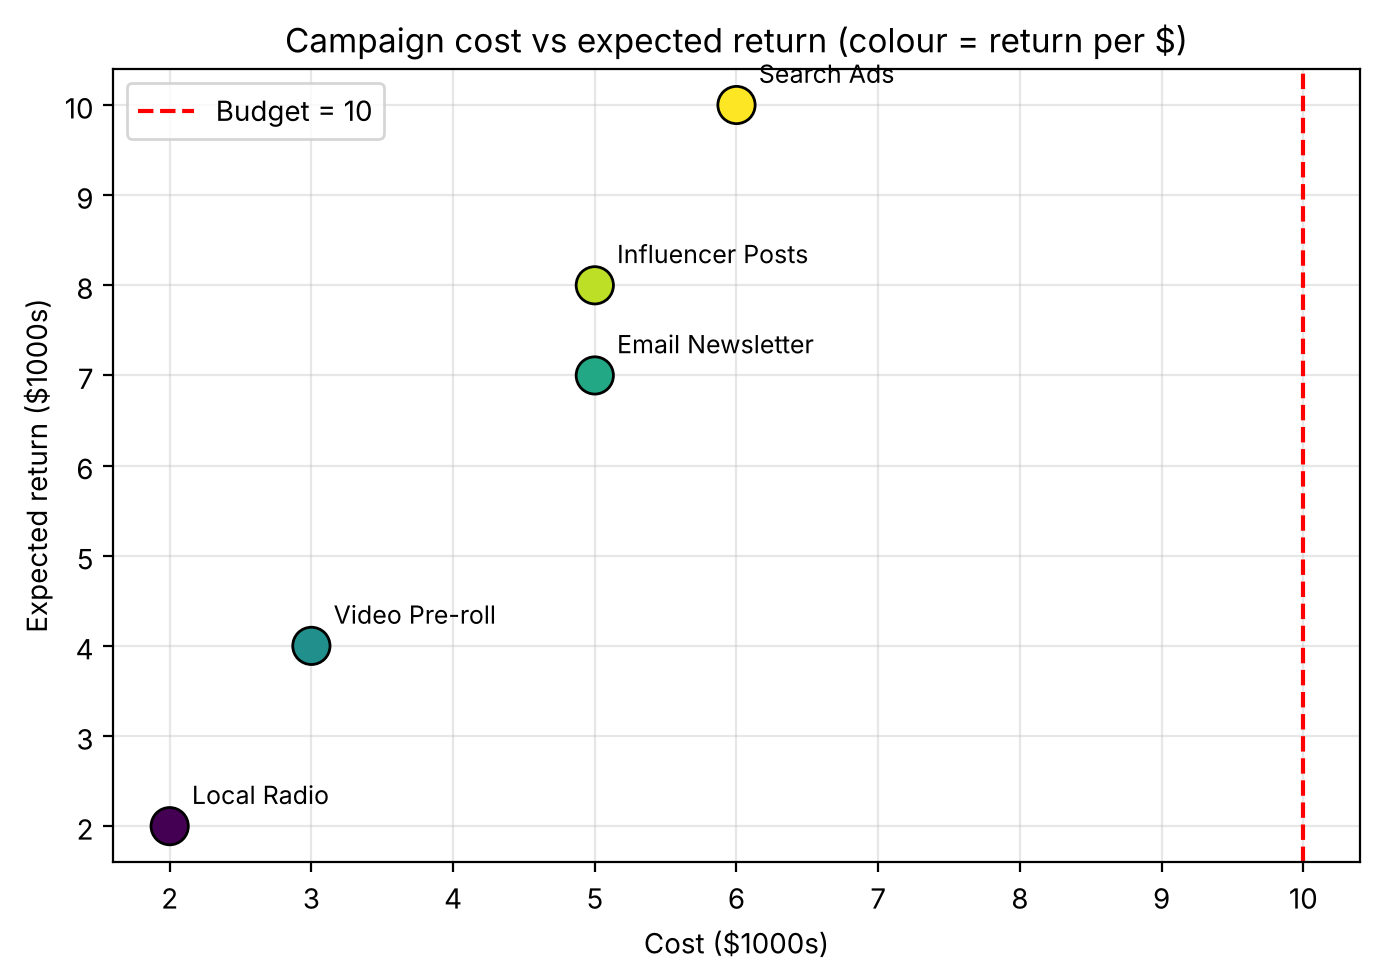

In [14]:
# ---- Figure 1: campaign cost vs expected return ----
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(costs, returns, s=180, c=returns / costs, cmap="viridis", edgecolor="k", zorder=3)
for i, nm in enumerate(names):
    ax.annotate(nm, (costs[i], returns[i]), textcoords="offset points", xytext=(8, 8), fontsize=9)
ax.axvline(BUDGET, color="red", ls="--", label=f"Budget = {BUDGET}")
ax.set_xlabel("Cost ($1000s)"); ax.set_ylabel("Expected return ($1000s)")
ax.set_title("Campaign cost vs expected return (colour = return per $)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

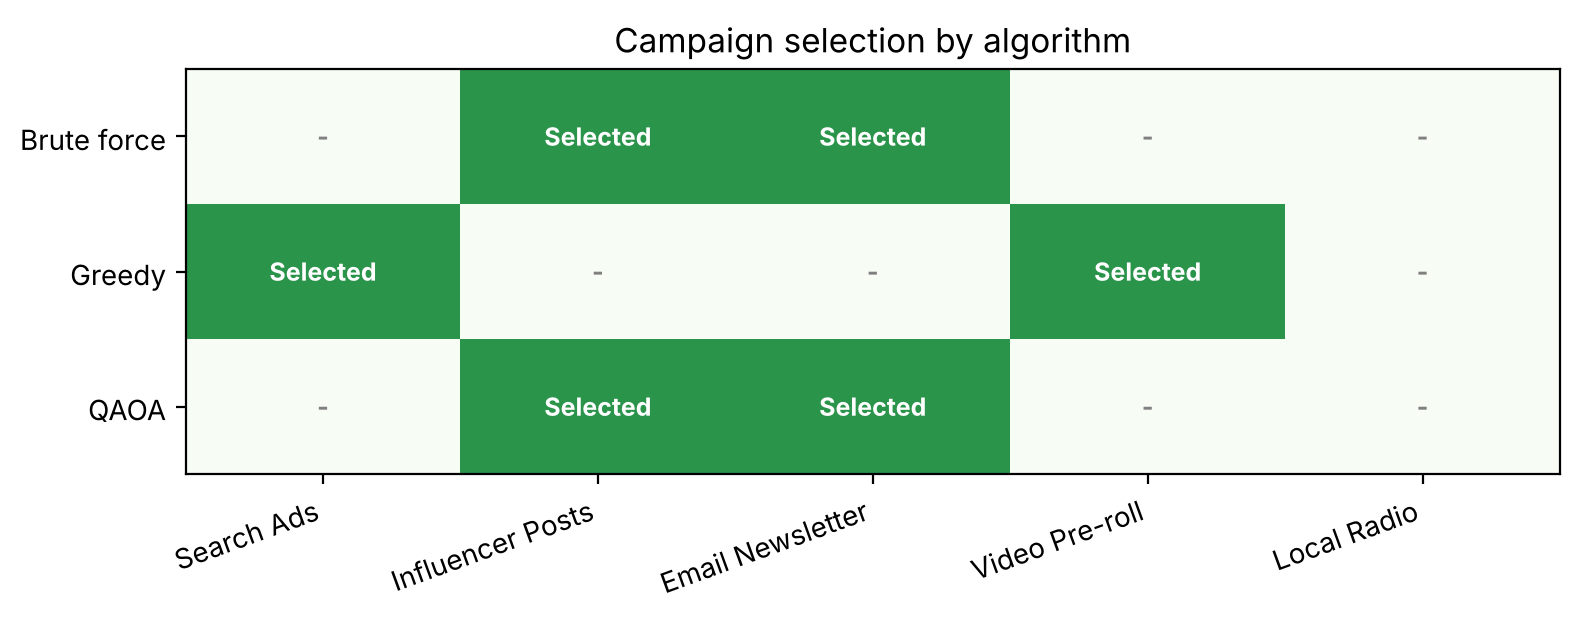

In [15]:
# ---- Figure 2: which campaigns each algorithm selected ----
methods = ["Brute force", "Greedy", "QAOA"]
sel_matrix = np.array([bf_x, gr_x, qaoa_x])
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(sel_matrix, cmap="Greens", vmin=0, vmax=1.4, aspect="auto")
ax.set_xticks(range(n)); ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(methods)
for i in range(3):
    for j in range(n):
        ax.text(j, i, "Selected" if sel_matrix[i, j] else "-", ha="center", va="center",
                color="white" if sel_matrix[i, j] else "gray", fontsize=9, fontweight="bold")
ax.set_title("Campaign selection by algorithm")
plt.tight_layout(); plt.show()

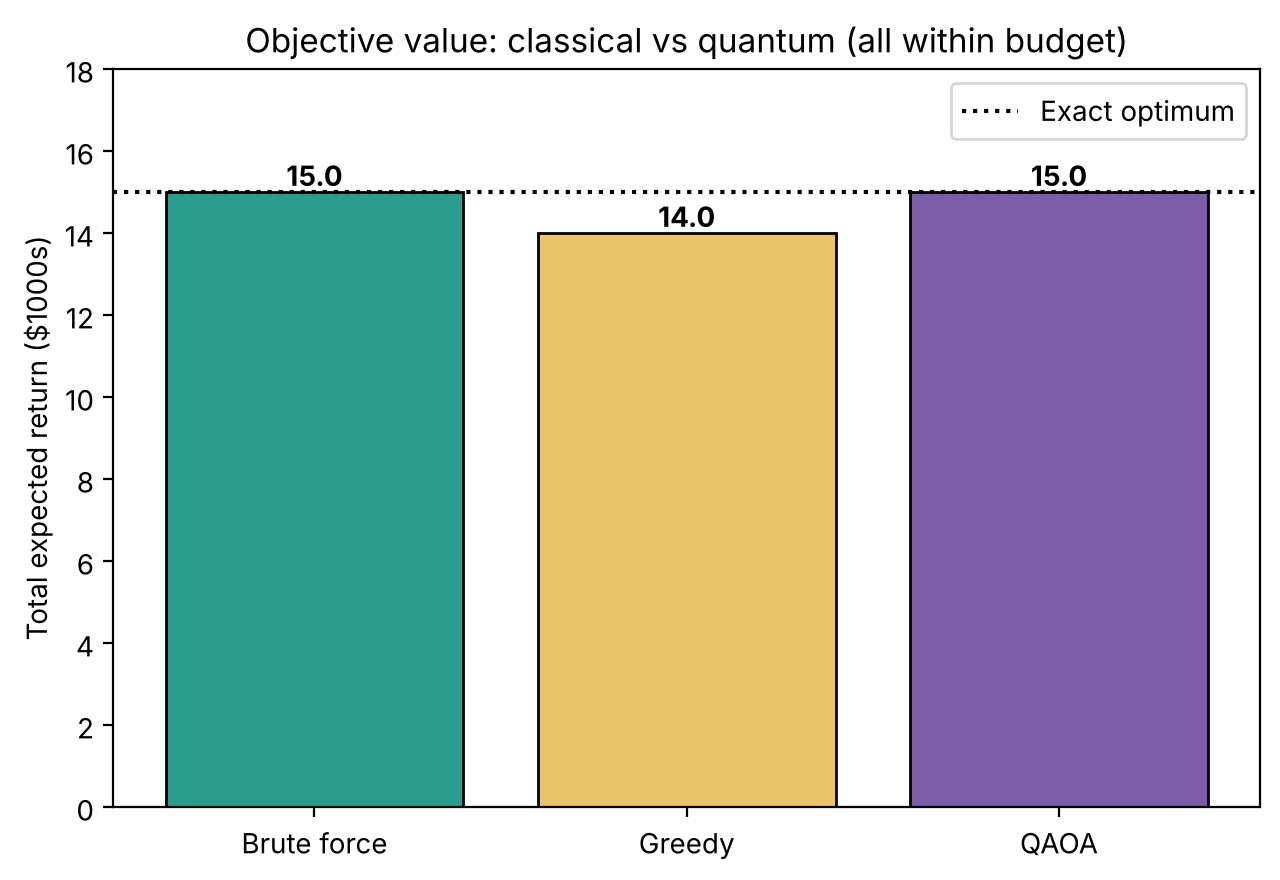

In [16]:
# ---- Figure 3: objective value (total return of the feasible solution) per method ----
vals = [bf_r, evaluate(gr_x)[1], q_ret]
colors = ["#2a9d8f", "#e9c46a", "#7b5ea7"]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(methods, vals, color=colors, edgecolor="k")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.1f}", ha="center", fontweight="bold")
ax.axhline(bf_r, color="k", ls=":", label="Exact optimum")
ax.set_ylabel("Total expected return ($1000s)")
ax.set_title("Objective value: classical vs quantum (all within budget)")
ax.legend(); ax.set_ylim(0, max(vals) * 1.2)
plt.tight_layout(); plt.show()

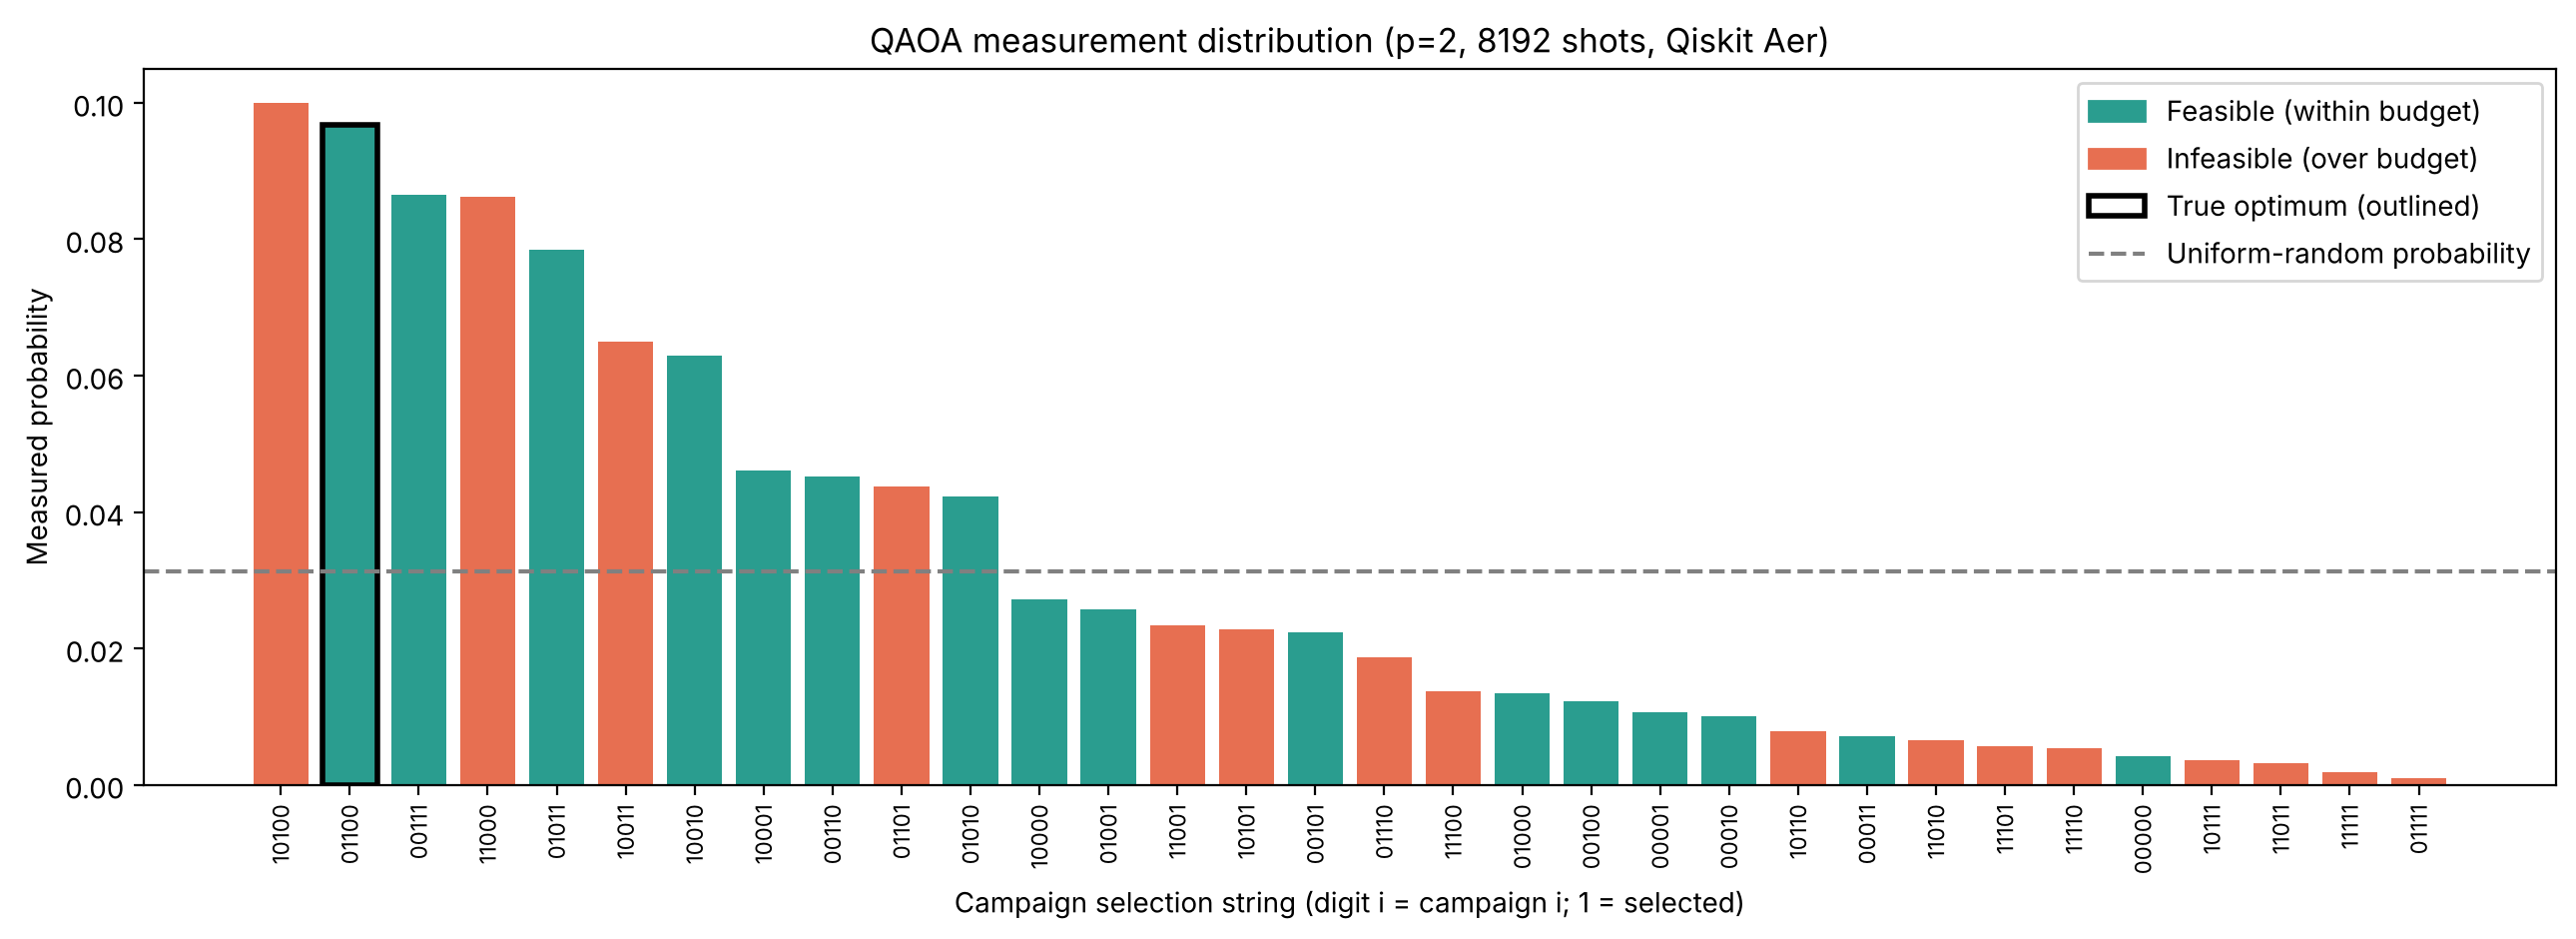

In [17]:
# ---- Figure 4: QAOA measurement probability distribution ----
# Show all 2^n campaign bitstrings, sorted by probability; feasible = green, infeasible = red, true optimum outlined
dist = results_df.copy()
all_x = ["".join(map(str, c)) for c in itertools.product([0, 1], repeat=n)]
missing = [s for s in all_x if s not in set(dist["x (x0..x4)"])]
for s in missing:
    xx = np.array([int(ch) for ch in s]); c_, r_, ok_ = evaluate(xx)
    dist.loc[len(dist)] = {"x (x0..x4)": s, "Qiskit string (q4..q0)": s[::-1], "Selected": "", "Cost ($k)": c_,
                           "Return ($k)": r_, "Feasible": ok_, "Counts": 0, "Probability": 0.0}
dist = dist.sort_values("Probability", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 4.8))
cols = ["#2a9d8f" if ok else "#e76f51" for ok in dist["Feasible"]]
bars = ax.bar(range(len(dist)), dist["Probability"], color=cols, edgecolor=["k" if s == opt_str else "none" for s in dist["x (x0..x4)"]], linewidth=2)
ax.set_xticks(range(len(dist))); ax.set_xticklabels(dist["x (x0..x4)"], rotation=90, fontsize=8)
ax.axhline(1 / 2 ** n, color="gray", ls="--", label="Uniform-random probability")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a9d8f", label="Feasible (within budget)"), Patch(color="#e76f51", label="Infeasible (over budget)"),
                   Patch(facecolor="white", edgecolor="k", linewidth=2, label="True optimum (outlined)"),
                   plt.Line2D([0], [0], color="gray", ls="--", label="Uniform-random probability")])
ax.set_xlabel("Campaign selection string (digit i = campaign i; 1 = selected)"); ax.set_ylabel("Measured probability")
ax.set_title(f"QAOA measurement distribution (p={P_LAYERS}, {SHOTS_FINAL} shots, Qiskit Aer)")
plt.tight_layout(); plt.show()

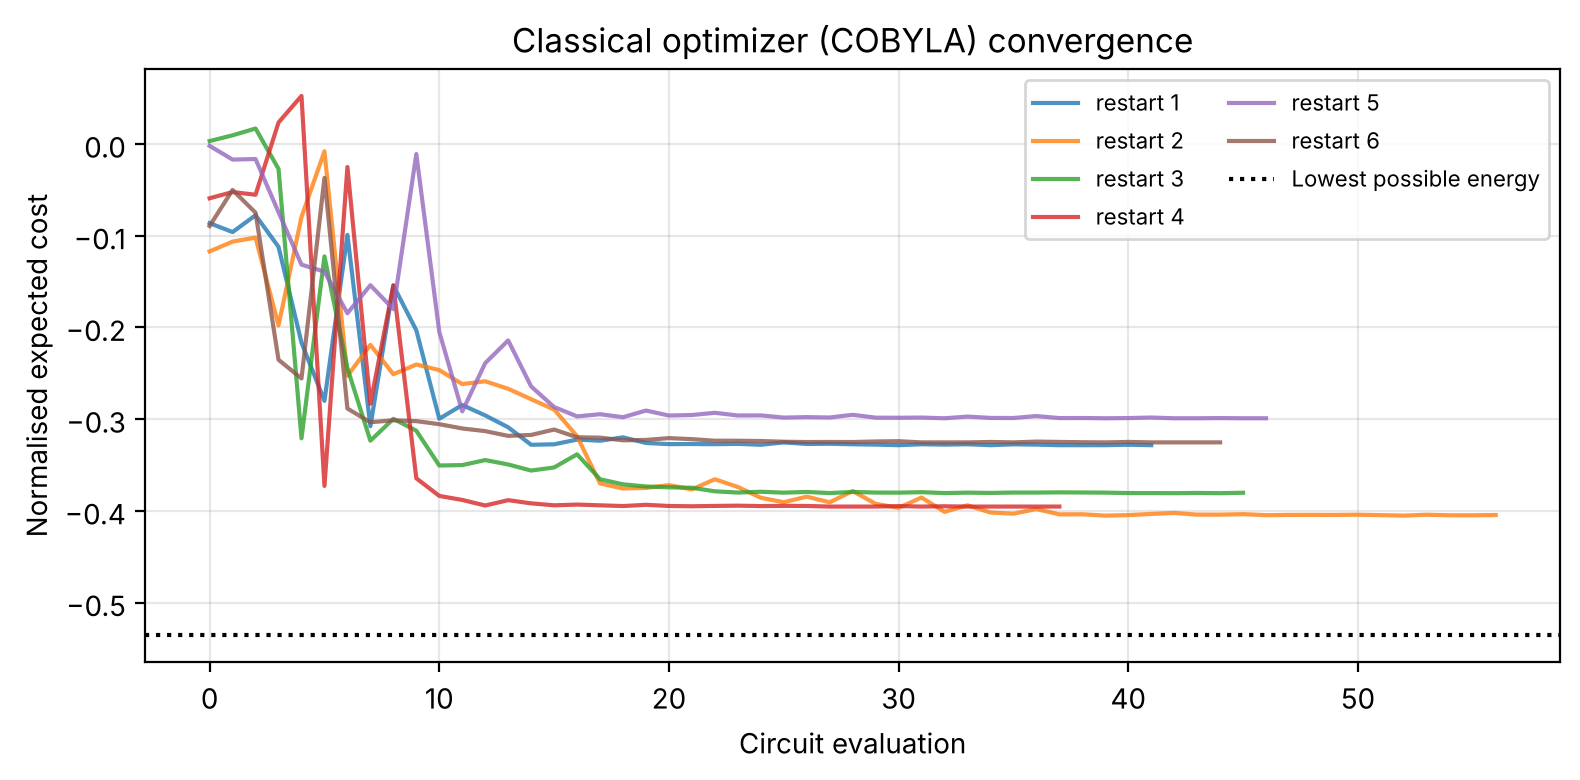

In [18]:
# ---- Figure 5: optimizer convergence (each restart) ----
fig, ax = plt.subplots(figsize=(8, 4))
for i, tr in enumerate(history_all):
    ax.plot(tr, alpha=0.8, label=f"restart {i+1}")
ax.axhline(f_norm.min(), color="k", ls=":", label="Lowest possible energy")
ax.set_xlabel("Circuit evaluation"); ax.set_ylabel("Normalised expected cost")
ax.set_title("Classical optimizer (COBYLA) convergence"); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. The QAOA Circuit

Below is the actual circuit that was simulated (with the optimized angles substituted in). Reading it left to right:

| Element | Meaning |
|---|---|
| **Qubits $q_0 \dots q_{N-1}$** | One qubit per campaign (qubit $i$ ↔ campaign $i$). A qubit in state $\lvert 1\rangle$ means "campaign selected". |
| **H (Hadamard)** | Puts every qubit into an equal superposition, so all $2^N$ campaign combinations are "tried" simultaneously. |
| **Cost layer** (boxed `PauliEvolutionGate`) | Applies $e^{-i\gamma H_C}$. It adds a phase to each combination according to its penalised cost, via parameterised $Z$-rotations and entangling gates (CNOT ladders). The angle $\gamma$ controls how strongly cost is imprinted. |
| **Mixer layer** (`RX(2β)` on every qubit) | Rotates each qubit around the X axis, mixing amplitudes between different combinations so that cost information can interfere into higher probabilities for good solutions. |
| **Parameterised rotations** | $\gamma_\ell$ and $\beta_\ell$ are tuned by the classical optimizer. |
| **Measurement** | Each qubit is measured to a classical bit, giving one candidate campaign selection per shot. Repeating many shots gives the probability distribution in Figure 4. |

(The cost layer is drawn as one box for readability. The transpiled circuit that actually runs on Aer is much deeper; its gate counts were printed in Section 5.3.)

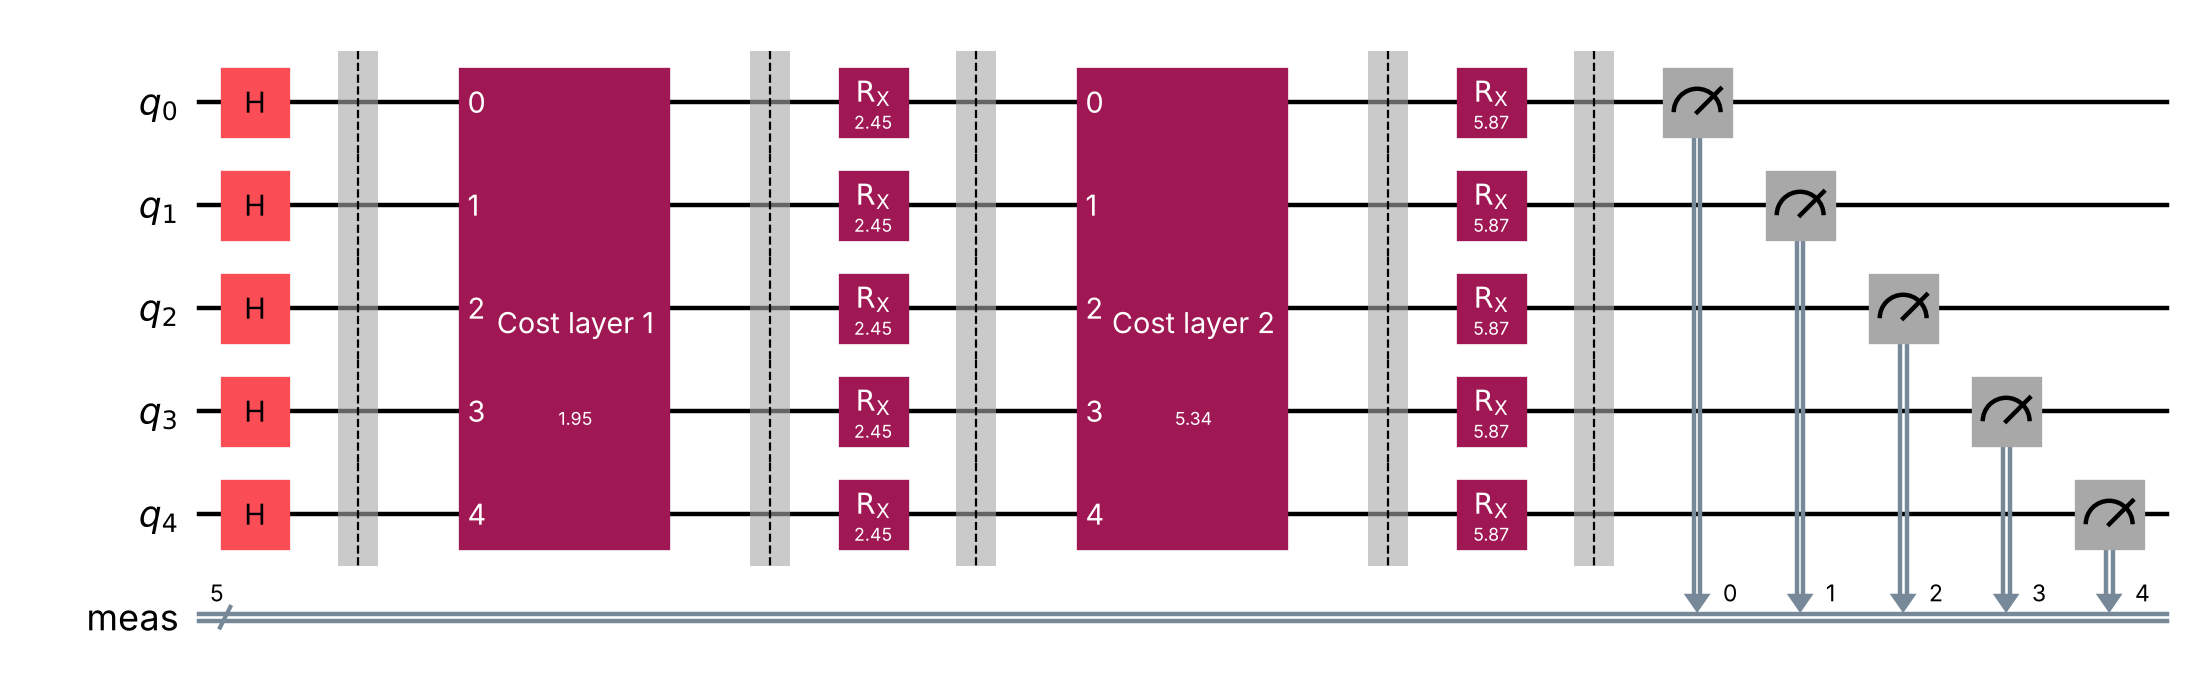

In [19]:
display_qc, dg, db = build_qaoa(P_LAYERS, measure=True)
display_qc = display_qc.assign_parameters(dict(zip(list(dg) + list(db), opt_theta)))
display_qc.draw("mpl", fold=-1, scale=0.8, style="iqp")

First three terms of the cost Hamiltonian: ['IIIIZ', 'IIIZI', 'IIIZZ']


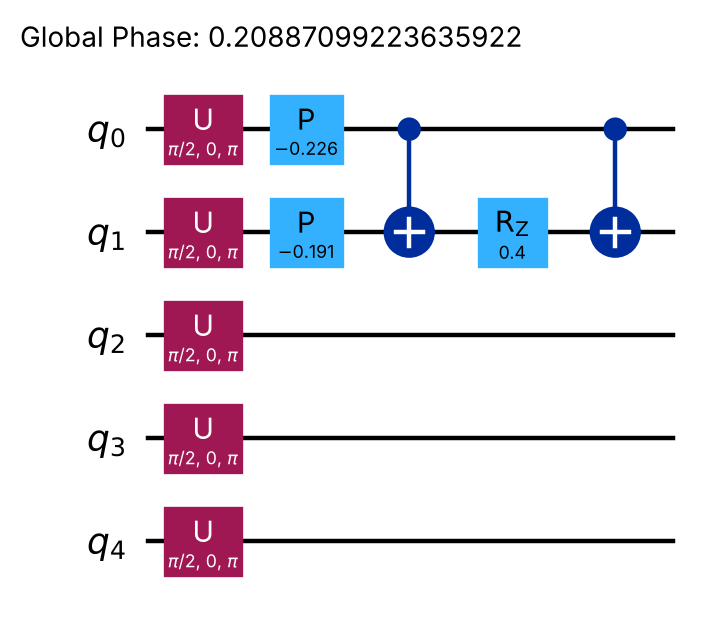

In [20]:
# A closer look at what ONE cost layer is made of (first few Pauli terms only, to keep the picture readable)
demo = QuantumCircuit(N_QUBITS)
demo.h(range(N_QUBITS))
small_op = SparsePauliOp(H_evolve.paulis[:3], np.real(H_evolve.coeffs)[:3])
demo.append(PauliEvolutionGate(small_op, time=float(opt_theta[0])), range(N_QUBITS))
print("First three terms of the cost Hamiltonian:", small_op.paulis.to_labels())
demo.decompose(reps=2).draw("mpl", fold=-1, scale=0.8, style="iqp")

## 9. Conclusion

### What the experiment demonstrated
* A marketing budget-allocation problem can be written as a **0/1 binary optimization** problem, converted into a **cost Hamiltonian**, and attacked with **QAOA** using Qiskit and Qiskit Aer.
* Handling the **inequality** budget constraint correctly matters. The naive squared penalty $P(\sum c_i x_i - B)^2$ encodes an *equality* and is wrong. We used either a one-sided hinge penalty (5 qubits) or a slack-variable QUBO (more qubits), and **verified numerically** that the penalised cost function's minimum equals the brute-force optimum.
* QAOA outputs a *probability distribution* over bitstrings, not a single answer. Some measured bitstrings are infeasible, and they must be **detected and discarded** rather than reported as valid. This notebook does that explicitly.

### Classical vs quantum results
The live results are in the Section 6 table and the printed verdicts. Read them rather than trusting any pre-written claim:
* **Brute force** is exact but its cost grows as $2^n$.
* **Greedy** is very fast but offers no guarantee, and on data like the default set it can select a worse combination.
* **QAOA** is a heuristic. Depending on $p$, the penalty, the optimizer, the starting angles and the number of shots, it may or may not place high probability on the optimal bitstring. Its probability on the true optimum, compared with the $1/32$ chance of a uniform random guess, shows how much the circuit actually learned.

### Limitations of quantum simulation
* A simulator on a classical computer must track $2^N$ amplitudes, so it cannot scale and offers **no speed advantage**. The QAOA timings here are slower than the classical ones.
* Real hardware adds **noise, limited connectivity and shallow depth limits**. The higher-order $Z$ terms of the hinge penalty (and the many two-qubit gates of a slack QUBO) make the circuit deeper and more error-prone.
* QAOA performance depends on **parameter optimization**, which can get stuck in local minima, and shot noise makes the objective stochastic.

### Why a 5-qubit simulation does not prove quantum advantage
Five variables have only 32 combinations. Brute force solves this instantly, and any laptop can do so. Quantum advantage is a statement about **asymptotic scaling on large problems compared with the best classical algorithms**. A tiny problem solved by a classical simulation of a quantum circuit says nothing about that. This project is an educational demonstration of *how* QAOA is formulated, built, run and evaluated honestly. It is not evidence that quantum computers beat classical methods for marketing optimization.

### Ideas to extend the project
Try `P_LAYERS = 1` vs `2` vs `3`; change `QAOA_MODE = "slack_qubo"` to compare qubit counts; change the budget or data; vary the penalty; or add a noise model from `qiskit_aer.noise` to see what happens on imperfect hardware.